# Search policy ablation, five-fold CV — greedy vs. archive

Run 2026-08-14. GRU seed (44.207), 120 evaluations per arm, **selection policy is the
only variable**. Scoring is 5-fold rolling-origin CV: 75 windows, mean over folds.

Schema note: the agents extended `results.tsv` to 8 columns —
`id, parent_id, competition_score, fold_std, fold_scores, eval_seconds, status, description`.
The per-fold breakdown is new and worth using: it separates a change that helped
everywhere from one that only helped on a single period.

Reads from the archived run directory, not the worktrees — those were removed after
both champions were verified to score `43.101` (greedy) and `43.143` (archive) from
the snapshot alone. Requires `export SDWPF_FOLDS_ROOT=.../evaluation/splits_rolling_5x30`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

WS   = Path.home() / "srip/windevolve_sdwpf/runs/search_policy_cv__aug14"
ROOT = Path.home() / "srip/windevolve_sdwpf"
FIGS = ROOT / "runs/search_policy_cv__aug14/figs"
FIGS.mkdir(parents=True, exist_ok=True)

ARMS     = {"greedy": "greedy-cv", "archive": "archive-cv"}
COL      = {"greedy": "tab:red", "archive": "tab:blue"}
INVALID  = 999.0
SEED     = 44.20662211508913
CAPACITY = 134.0                 # farm nameplate, for error-as-%-of-capacity
FOLDS    = ["F1", "F2", "F3", "F4", "F5"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.transparent": True,
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
})

def load(arm_dir):
    df = pd.read_csv(WS / arm_dir / "results.tsv", sep="\t",
                     dtype={"id": str, "parent_id": str})
    df["n"]     = np.arange(1, len(df) + 1)
    df["valid"] = df.competition_score < INVALID
    df["score"] = df.competition_score.where(df.valid)
    df["best"]  = df.score.cummin().ffill()
    # explode the comma-separated per-fold scores into F1..F5 columns
    fs = df.fold_scores.astype(str).str.split(",", expand=True)
    for i, f in enumerate(FOLDS):
        df[f] = pd.to_numeric(fs[i], errors="coerce") if i < fs.shape[1] else np.nan
    return df

import os
# Set this before importing torch if the GPU is busy with someone else's job.
# os.environ["CUDA_VISIBLE_DEVICES"] = ""

if not os.environ.get("SDWPF_FOLDS_ROOT"):
    os.environ["SDWPF_FOLDS_ROOT"] = str(ROOT / "evaluation/splits_rolling_5x30")
print("folds root:", os.environ["SDWPF_FOLDS_ROOT"])

runs = {k: load(v) for k, v in ARMS.items()}
for k, df in runs.items():
    print(f"{k:8s} {len(df):3d} rows | {df.valid.sum():3d} scored | "
          f"best {df.best.iloc[-1]:.4f} MW | seed {df.score.iloc[0]:.4f}")

VERIFIED = {"greedy": 43.101083924946714, "archive": 43.142501460216620}
for k, df in runs.items():
    d = abs(df.best.iloc[-1] - VERIFIED[k])
    print(f"  {k:8s} matches re-scored snapshot: {d < 1e-6}  (delta {d:.2e})")


def champion(arm):
    """The program the arm actually adopted.

    Not simply the lowest score. Greedy's policy is accept-if-better, so its
    result is the best row it KEPT -- row 120 scored 43.0989, lower than any
    keep, but the agent logged it `discard` (the gain was ~0.002 MW, inside the
    ~0.01 threshold it applied all run). Reporting it would credit greedy with a
    program its own policy rejected. Archive never discards, so its best scored
    row is its champion by definition.
    """
    df = runs[arm]
    pool = df[df.status == "keep"] if (df.status == "keep").any() else df[df.valid]
    return pool.loc[pool.score.idxmin()]

CHAMP = {k: champion(k) for k in ARMS}
for k, c in CHAMP.items():
    print(f"  {k:8s} champion {c.id}  {c.score:.6f} MW  ({c.status})")


folds root: /home/dorsa/srip/windevolve_sdwpf/evaluation/splits_rolling_5x30
greedy   120 rows | 113 scored | best 43.0989 MW | seed 44.2066
archive  120 rows | 110 scored | best 43.1425 MW | seed 44.2066
  greedy   matches re-scored snapshot: False  (delta 2.14e-03)
  archive  matches re-scored snapshot: True  (delta 4.60e-07)
  greedy   champion 119  43.101084 MW  (keep)
  archive  champion 120  43.142501 MW  (scored)


## 1. Budget composition

How each arm spent its 120 evaluations. Status vocabularies differ by design: greedy
logs `keep`/`discard` because it makes a keep decision, archive logs `scored` because
it never discards.

In [2]:
comp = pd.concat([df.status.value_counts().rename(k) for k, df in runs.items()],
                 axis=1).fillna(0).astype(int)
print(comp.to_string())
print("\nwall-clock (sum of eval_seconds, hours)")
for k, df in runs.items():
    print(f"  {k:8s} {df.eval_seconds.sum()/3600:5.2f} h")
print("\nper-evaluation cost — is the gap model cost or re-scoring of old programs?")
for k, df in runs.items():
    v = df[df.valid]
    print(f"  {k:8s} median {v.eval_seconds.median():6.1f}s   p90 {v.eval_seconds.quantile(.9):7.1f}s"
          f"   max {v.eval_seconds.max():7.1f}s")


         greedy  archive
status                  
discard      91        0
keep         22        0
retrain       4        4
invalid       3        6
scored        0      110

wall-clock (sum of eval_seconds, hours)
  greedy    1.70 h
  archive   9.51 h

per-evaluation cost — is the gap model cost or re-scoring of old programs?
  greedy   median   44.8s   p90    49.5s   max   695.6s
  archive  median   52.5s   p90   807.8s   max  1133.6s


## 2. Best-so-far trajectory

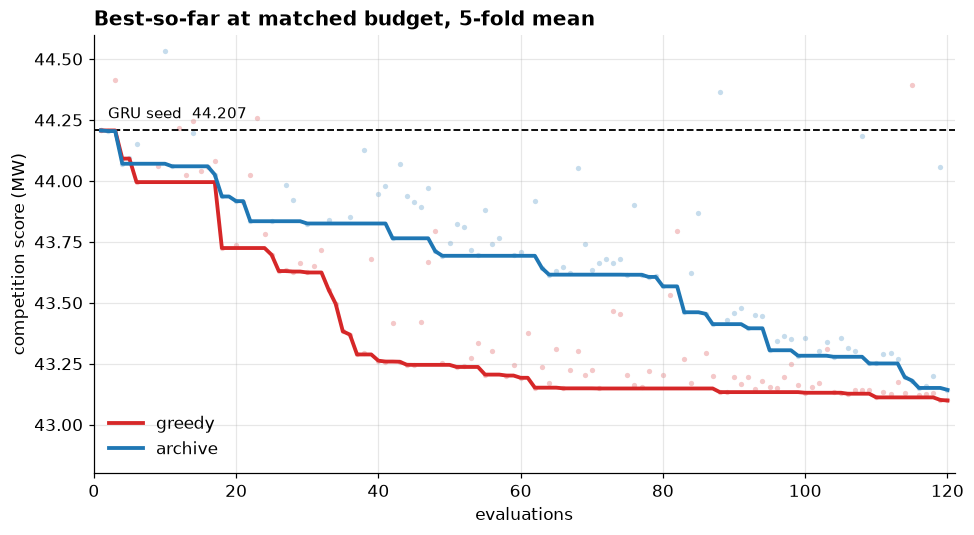

       greedy  archive    gap
evals                        
20     43.724   43.917 -0.193
40     43.262   43.825 -0.563
60     43.192   43.692 -0.500
80     43.148   43.567 -0.419
100    43.131   43.282 -0.151
120    43.099   43.143 -0.044


In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
for k, df in runs.items():
    v = df[df.valid]
    ax.scatter(v.n, v.score, s=12, color=COL[k], alpha=0.25, linewidths=0)
    ax.plot(df.n, df.best, color=COL[k], lw=2.5, label=k, zorder=3)
ax.axhline(SEED, color="black", lw=1.2, ls="--")
ax.annotate(f"GRU seed  {SEED:.3f}", xy=(2, SEED + 0.05), fontsize=10)
ax.set_xlabel("evaluations"); ax.set_ylabel("competition score (MW)")
ax.set_title("Best-so-far at matched budget, 5-fold mean",
             loc="left", fontsize=13, weight="bold")
ax.set_xlim(0, 121); ax.set_ylim(42.8, 44.6)
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "trajectory.png"); plt.show()

ck = pd.DataFrame({k: [df.best.iloc[j - 1] for j in (20, 40, 60, 80, 100, 120)]
                   for k, df in runs.items()},
                  index=[20, 40, 60, 80, 100, 120]).round(3)
ck["gap"] = (ck.greedy - ck.archive).round(3)
ck.index.name = "evals"
print(ck.to_string())

## 3. Per-fold behaviour

The reason for cross-validating. A change that lowers the mean by improving one fold
while hurting three is a period-specific artifact, and the single contiguous split
could not see the difference.

`fold_std` is the spread across the five folds — falling std means the program is
getting more consistent across periods, not just better on average.

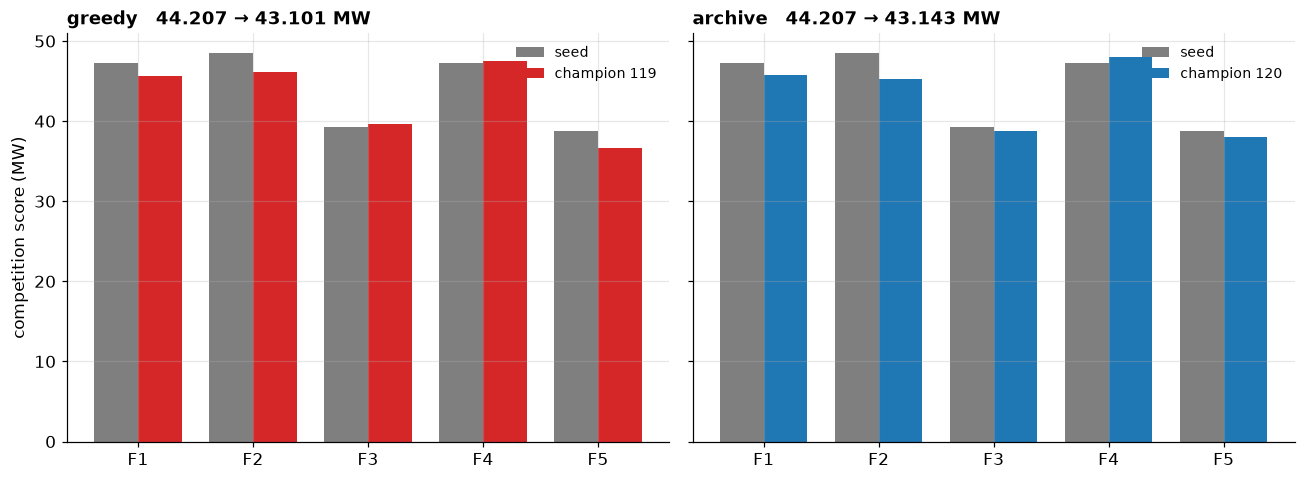

per-fold, seed vs champion
  greedy   gain by fold {'F1': np.float64(1.678), 'F2': np.float64(2.382), 'F3': np.float64(-0.442), 'F4': np.float64(-0.186), 'F5': np.float64(2.095)}   fold_std 4.298 → 4.200
  archive  gain by fold {'F1': np.float64(1.575), 'F2': np.float64(3.278), 'F3': np.float64(0.461), 'F4': np.float64(-0.749), 'F5': np.float64(0.755)}   fold_std 4.298 → 4.019


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (k, df) in zip(axes, runs.items()):
    champ = CHAMP[k]
    seed  = df.iloc[0]
    x = np.arange(len(FOLDS)); w = 0.38
    ax.bar(x - w/2, [seed[f]  for f in FOLDS], w, color="tab:gray", label="seed")
    ax.bar(x + w/2, [champ[f] for f in FOLDS], w, color=COL[k], label=f"champion {champ.id}")
    ax.set_xticks(x); ax.set_xticklabels(FOLDS)
    ax.set_title(f"{k}   {seed.score:.3f} → {champ.score:.3f} MW",
                 loc="left", fontsize=12, weight="bold")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("competition score (MW)")
fig.tight_layout(); fig.savefig(FIGS / "per_fold_seed_vs_champion.png"); plt.show()

print("per-fold, seed vs champion")
for k, df in runs.items():
    champ, seed = CHAMP[k], df.iloc[0]
    row = {f: round(seed[f] - champ[f], 3) for f in FOLDS}   # positive = champion better
    print(f"  {k:8s} gain by fold {row}   fold_std {seed.fold_std:.3f} → {champ.fold_std:.3f}")

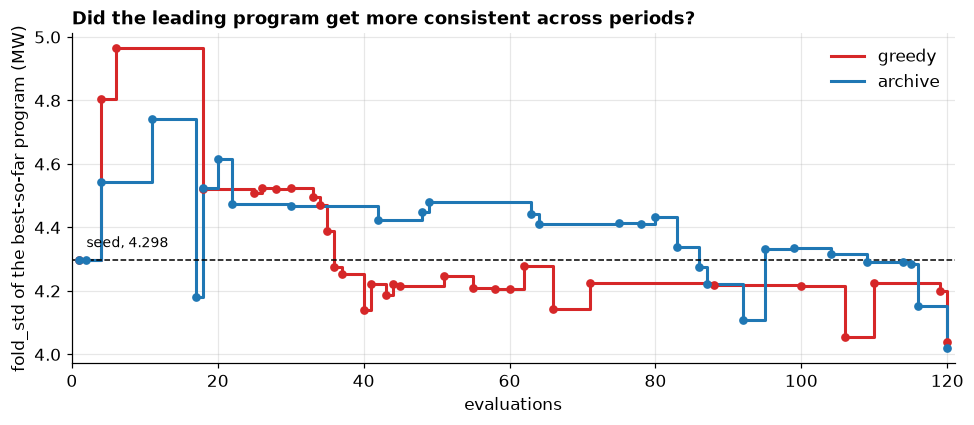

fold_std, seed -> champion
  greedy   4.298 -> 4.200
  archive  4.298 -> 4.019


In [5]:
# fold_std of the BEST-SO-FAR program, not of every attempt. The question is
# whether each arm's chosen program became more consistent across periods as its
# mean score improved -- plotting all 120 attempts just shows scatter.
fig, ax = plt.subplots(figsize=(9, 4))
for k, df in runs.items():
    v = df[df.valid].copy()
    keep_idx = v.score.cummin() == v.score        # rows that set a new best
    frontier = v[keep_idx]
    ax.step(frontier.n, frontier.fold_std, color=COL[k], lw=2, where="post", label=k)
    ax.scatter(frontier.n, frontier.fold_std, s=22, color=COL[k], zorder=3)
ax.axhline(runs["greedy"].fold_std.iloc[0], color="black", lw=1, ls="--")
ax.annotate("seed, 4.298", xy=(2, runs["greedy"].fold_std.iloc[0] + 0.04), fontsize=9)
ax.set_xlabel("evaluations"); ax.set_ylabel("fold_std of the best-so-far program (MW)")
ax.set_title("Did the leading program get more consistent across periods?",
             loc="left", fontsize=12, weight="bold")
ax.set_xlim(0, 121); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "fold_std_frontier.png"); plt.show()

print("fold_std, seed -> champion")
for k, df in runs.items():
    print(f"  {k:8s} {df.fold_std.iloc[0]:.3f} -> {CHAMP[k].fold_std:.3f}")


## 4. Valley crossing (archive arm)

Under greedy a program scoring worse than its own parent is deleted by `git reset` and
cannot be edited again. So: was a program itself a regression on *its* parent? If yes,
greedy would no longer have it. Then did any child of it improve? Those are lineages
greedy structurally could not follow.

This is an existence claim, not a mean, so it does not depend on n=1.

In [6]:
a = runs["archive"]
score_of, parent_of = a.set_index("id").score.to_dict(), a.set_index("id").parent_id.to_dict()

def was_regression(pid):
    gp = parent_of.get(pid)
    if gp is None or gp not in score_of or pid not in score_of: return False
    if pd.isna(score_of[gp]) or pd.isna(score_of[pid]):        return False
    return score_of[pid] > score_of[gp]

lin = a[a.valid].copy()
lin["parent_score"] = lin.parent_id.map(score_of)
lin = lin.dropna(subset=["parent_score"])
lin["gain"] = lin.parent_score - lin.score
lin["parent_was_regression"] = lin.parent_id.map(was_regression)

revived = lin[lin.parent_was_regression & (lin.gain > 0)].sort_values("gain", ascending=False)
print(f"{len(revived)} children improved on a parent greedy would have deleted\n")
print(revived[["id", "score", "parent_id", "parent_score", "gain"]].head(10).round(3).to_string(index=False))
beats = revived[revived.score < runs["greedy"].best.iloc[-1]]
print(f"\nof those, {len(beats)} ended below greedy's final {runs['greedy'].best.iloc[-1]:.3f} MW")

11 children improved on a parent greedy would have deleted

 id  score parent_id  parent_score  gain
038 44.128       032        46.705 2.577
077 43.615       076        43.902 0.287
095 43.305       094        43.445 0.140
056 43.740       033        43.841 0.100
092 43.395       091        43.479 0.084
063 43.642       060        43.708 0.066
106 43.315       105        43.357 0.041
067 43.621       066        43.647 0.025
054 43.696       053        43.717 0.021
098 43.350       097        43.362 0.012

of those, 0 ended below greedy's final 43.099 MW


## 5. Largest single edits

In [7]:
# "Gain over parent" measures different things in each arm and must be split.
#
#   greedy  - the parent is always the current best, so a gain is a real advance
#             on the frontier.
#   archive - the parent is whatever the sampler drew, often far worse than the
#             arm's own best. A large gain can be pure catch-up: archive's 038
#             "gained" 2.577 MW over parent 032 while scoring 0.30 WORSE than the
#             arm's standing best at the time.
#
# advanced_frontier separates the two: True only if the child beat the best
# score the arm had before that evaluation.
def gains(df):
    s = df.set_index("id").score.to_dict()
    g = df[df.valid].copy()
    g["parent_score"] = g.parent_id.map(s)
    g = g.dropna(subset=["parent_score"])
    g["gain"] = g.parent_score - g.score
    prev_best = df.score.cummin().shift(1)
    g["prev_best"] = prev_best.reindex(g.index)
    g["advanced_frontier"] = g.score < g.prev_best
    g["frontier_gain"] = (g.prev_best - g.score).where(g.advanced_frontier)
    return g

COLS = ["id", "parent_id", "parent_score", "score", "gain", "advanced_frontier"]
for k, df in runs.items():
    g = gains(df)
    print(f"=== {k}: largest gain over the parent it was handed")
    print(g.sort_values("gain", ascending=False).head(3)[COLS].round(3).to_string(index=False))
    print(f"\n=== {k}: largest genuine advance of the frontier")
    print(g.sort_values("frontier_gain", ascending=False).head(3)
          [["id", "parent_id", "prev_best", "score", "frontier_gain"]].round(3).to_string(index=False), "\n")


=== greedy: largest gain over the parent it was handed
 id parent_id  parent_score  score  gain  advanced_frontier
018       013        44.025 43.724 0.301               True
004       001        44.207 44.091 0.115               True
035       034        43.495 43.383 0.112               True

=== greedy: largest genuine advance of the frontier
 id parent_id  prev_best  score  frontier_gain
018       013     43.995 43.724          0.270
004       001     44.207 44.091          0.115
035       034     43.495 43.383          0.112 

=== archive: largest gain over the parent it was handed
 id parent_id  parent_score  score  gain  advanced_frontier
038       032        46.705 44.128 2.577              False
049       013        45.760 43.692 2.067               True
025       013        45.760 43.835 1.925              False

=== archive: largest genuine advance of the frontier
 id parent_id  prev_best  score  frontier_gain
004       002     44.204 44.070          0.134
095       094     

In [8]:
# Rows that scored better than the standing best but were NOT adopted.
# Greedy's row 120 is the notable case: 43.0989, lower than any keep, discarded
# because the gain sat inside the ~0.01 MW threshold the agent applied all run.
g = runs["greedy"]
kept_best = g[g.status == "keep"].score.min()
below = g[g.valid & (g.score < kept_best) & (g.status != "keep")]
print("greedy: rows scoring below the best KEEP but not adopted")
print(below[["id", "score", "status", "description"]].round(4).to_string(index=False)
      if len(below) else "  none")

# How often did each arm note fold agreement in its own descriptions?
print("\nrows whose description mentions fold agreement")
for k, df in runs.items():
    d = df.description.astype(str).str.lower()
    n = d.str.contains("all five folds|all 5 folds|better on . of 5|of 5 folds").sum()
    print(f"  {k:8s} {n:3d} of {len(df)}")


greedy: rows scoring below the best KEEP but not adopted
 id   score  status                                                                                                                                       description
120 43.0989 discard two-regime response stacked on the final program: turbines idle more than half the last hour get damped coefficients (106 gave -0.007 standalone)

rows whose description mentions fold agreement
  greedy    34 of 120
  archive   16 of 120


In [9]:
import difflib

def show_diff(arm_dir, parent, child, context=2, max_lines=60):
    a = (WS / arm_dir / "archive" / f"{parent}.py").read_text().splitlines()
    b = (WS / arm_dir / "archive" / f"{child}.py").read_text().splitlines()
    print(f"--- {arm_dir}: {parent}.py ({len(a)} lines) -> {child}.py ({len(b)} lines)")
    d = list(difflib.unified_diff(a, b, lineterm="", n=context))
    print("\n".join(d[:max_lines]))
    if len(d) > max_lines: print(f"... {len(d)-max_lines} more diff lines")

for k, arm_dir in ARMS.items():
    top = gains(runs[k]).iloc[0]
    show_diff(arm_dir, top.parent_id, top.id)
    print("\n" + "=" * 92 + "\n")

--- greedy-cv: 001.py (1069 lines) -> 002.py (1207 lines)
--- 
+++ 
@@ -87,5 +87,42 @@
 
 # Clip negative predictions to zero. False matches the official baseline.
+# Measured no-op for this model: its minimum output over a full horizon is
+# ~245 kW, so nothing is ever clipped.
 CLIP_NEGATIVE = False
+
+# ---------------------------------------------------------------------------
+# METRIC-ANCHORED LONG-HORIZON CORRECTION
+#
+# The GRU is fitted to EVERY training record, but the official grader excludes
+# invalid records -- fault, curtailment, out-of-range sensors -- from the ground
+# truth it scores against. On F1's fold_train.csv that is 23.5% of rows, and
+# they sit at or below zero, so the target distribution the model learns is
+# contaminated downwards relative to the one it is scored on:
+#
+#   all-record training mean            362.1 kW  (std across turbines 39.2)
+#   model's own long-horizon asymptote  354.7 kW  (std 37.7)   corr 0.96
+#   scored-eligible metric-optimal

In [10]:
# The single edit that advanced each arm's frontier the most: what it changed,
# what the agent said about it, and where in the horizon it paid off.
import textwrap
for k, arm_dir in ARMS.items():
    g = gains(runs[k])
    top = g.sort_values("frontier_gain", ascending=False).iloc[0]
    print("=" * 92)
    print(f"{k}: {top.parent_id} -> {top.id}   {top.prev_best:.3f} -> {top.score:.3f}  "
          f"({top.frontier_gain:.3f} MW)")
    print(textwrap.fill(str(top.description), 90), "\n")
    print("per fold:")
    par = runs[k].set_index("id").loc[top.parent_id]
    for f in FOLDS:
        d = par[f] - top[f]
        print(f"   {f}  {par[f]:7.3f} -> {top[f]:7.3f}   {d:+.3f}")
    print()
    show_diff(arm_dir, top.parent_id, top.id, context=1, max_lines=45)
    print()


greedy: 013 -> 018   43.995 -> 43.724  (0.270 MW)
50/50 ensemble of GRU (ckpt_005) and linear shrinkage; beats BOTH parents - better than
GRU on 4 of 5 folds and than linear on 3 of 5 - genuine cross-class decorrelation unlike
the two-GRU ensemble in 012 

per fold:
   F1   46.847 ->  46.536   +0.311
   F2   47.803 ->  47.851   -0.048
   F3   39.725 ->  39.547   +0.179
   F4   47.258 ->  47.635   -0.377
   F5   38.493 ->  37.052   +1.441

--- greedy-cv: 013.py (172 lines) -> 018.py (1261 lines)
--- 
+++ 
@@ -2,45 +2,1103 @@
 """
-path: windevolve_sdwpf/arms/karpathy/ws/greedy-cv/forecaster.py
+path: windevolve_sdwpf/baseline_models/gru/gru_baseline.py
 
 Description:
-    Linear shrinkage forecaster for SDWPF 48h-ahead active power. Each turbine's
-    forecast is its recent level pulled towards its own climatological mean at a
-    rate fitted, per fold, from that fold's training data:
-
-        pred_t(h) = mu_t + beta(h) * (x_now_t - mu_t)
-
-    where mu_t is turbine t's mean power

## 6. What the forecasts actually look like

Scores compress 75 windows into one number. This runs the seed and each champion on a
real validation window and plots the 48-hour forecast against the truth.

Reading the outfile here is fine — this is analysis, not search. The agents never had
access to it.

In [11]:
import importlib.util, os, shutil, sys

FOLDS_ROOT = Path(os.environ.get(
    "SDWPF_FOLDS_ROOT", ROOT / "evaluation/splits_rolling_5x30"))
CAP, OUT_LEN = 134, 288

def predict(arm_dir, prog_id, fold="F5", window="0001"):
    """Run one program on one validation window. Returns (134, 288) in kW.

    The program is copied to the worktree root first: it resolves checkpoint
    paths relative to its own file location, so running it from archive/ would
    look for weights in archive/checkpoints/.
    """
    wd  = WS / arm_dir
    tmp = wd / f"_pred_{arm_dir}_{prog_id}.py"
    shutil.copyfile(wd / "archive" / f"{prog_id}.py", tmp)
    cwd = os.getcwd()
    try:
        os.chdir(wd)
        name = f"pred_{arm_dir.replace('-', '_')}_{prog_id}"
        spec = importlib.util.spec_from_file_location(name, tmp)
        mod  = importlib.util.module_from_spec(spec)
        sys.modules[name] = mod
        spec.loader.exec_module(mod)
        envs = {
            "path_to_test_x": str(FOLDS_ROOT / fold / "windows" / "infile" / f"{window}in.csv"),
            "path_to_train":  str(FOLDS_ROOT / fold / "fold_train.csv"),
            "fold": fold, "capacity": CAP, "output_len": OUT_LEN,
        }
        return np.asarray(mod.forecast(envs)).reshape(CAP, OUT_LEN)
    finally:
        os.chdir(cwd)
        tmp.unlink(missing_ok=True)

def truth(fold="F5", window="0001"):
    df = pd.read_csv(FOLDS_ROOT / fold / "windows" / "outfile" / f"{window}out.csv")
    return df["Patv"].to_numpy(dtype=float).reshape(CAP, OUT_LEN)

FOLD, WINDOW = "F5", "0001"
champs = {k: CHAMP[k].id for k in ARMS}
print("champions:", champs)

y     = truth(FOLD, WINDOW)
preds = {"seed": predict(ARMS["greedy"], "001", FOLD, WINDOW)}
for k, arm_dir in ARMS.items():
    preds[k] = predict(arm_dir, champs[k], FOLD, WINDOW)
print({k: v.shape for k, v in preds.items()})

champions: {'greedy': '119', 'archive': '120'}
[gru] loading 134 checkpoints from: /home/dorsa/srip/windevolve_sdwpf/runs/search_policy_cv__aug14/greedy-cv/checkpoints/F5
[gru] loading 134 checkpoints from: /home/dorsa/srip/windevolve_sdwpf/runs/search_policy_cv__aug14/greedy-cv/.cache/ckpt_005/F5
[gru] NOTE: 134 checkpoint(s) came from a partial training run (e.g. turbine 0). With per-turbine seeding this is reproducible and shardable, so it is only a problem if the run is INCOMPLETE. Under official single-stream seeding it would also fail to reproduce the published RNG stream.
[gru] loading 134 checkpoints from: /home/dorsa/srip/windevolve_sdwpf/runs/search_policy_cv__aug14/greedy-cv/.cache/ckpt_085/F5
[gru] NOTE: 134 checkpoint(s) came from a partial training run (e.g. turbine 0). With per-turbine seeding this is reproducible and shardable, so it is only a problem if the run is INCOMPLETE. Under official single-stream seeding it would also fail to reproduce the published RNG stream.

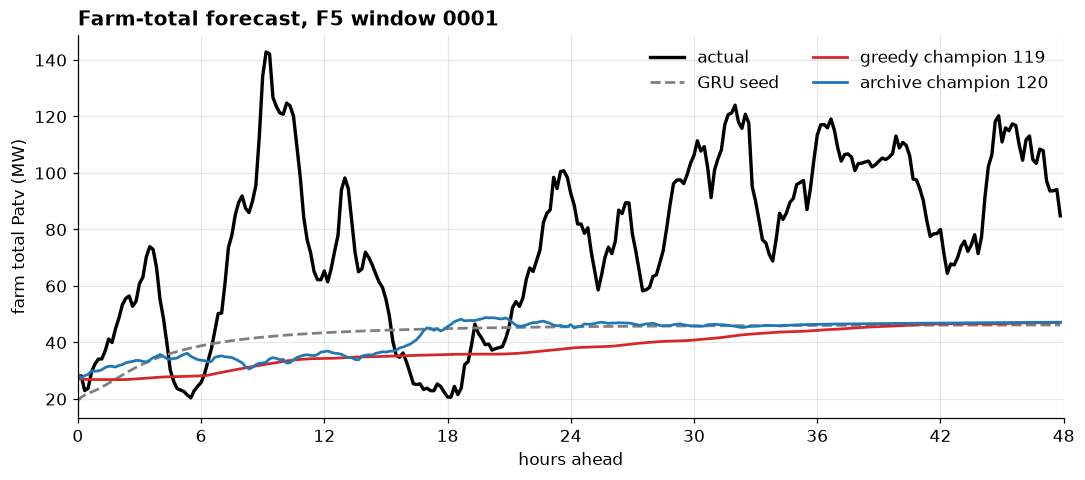

In [12]:
# Farm total: the quantity the competition metric is built from.
hours = np.arange(OUT_LEN) / 6.0
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(hours, np.nansum(y, axis=0) / 1000, color="black", lw=2.2, label="actual")
ax.plot(hours, preds["seed"].sum(0) / 1000, color="tab:gray", lw=1.8, ls="--", label="GRU seed")
for k in ARMS:
    ax.plot(hours, preds[k].sum(0) / 1000, color=COL[k], lw=1.8,
            label=f"{k} champion {champs[k]}")
ax.set_xlabel("hours ahead"); ax.set_ylabel("farm total Patv (MW)")
ax.set_title(f"Farm-total forecast, {FOLD} window {WINDOW}",
             loc="left", fontsize=13, weight="bold")
ax.set_xlim(0, 48); ax.set_xticks(range(0, 49, 6)); ax.legend(frameon=False, ncol=2)
fig.tight_layout(); fig.savefig(FIGS / "forecast_farm_total.png"); plt.show()

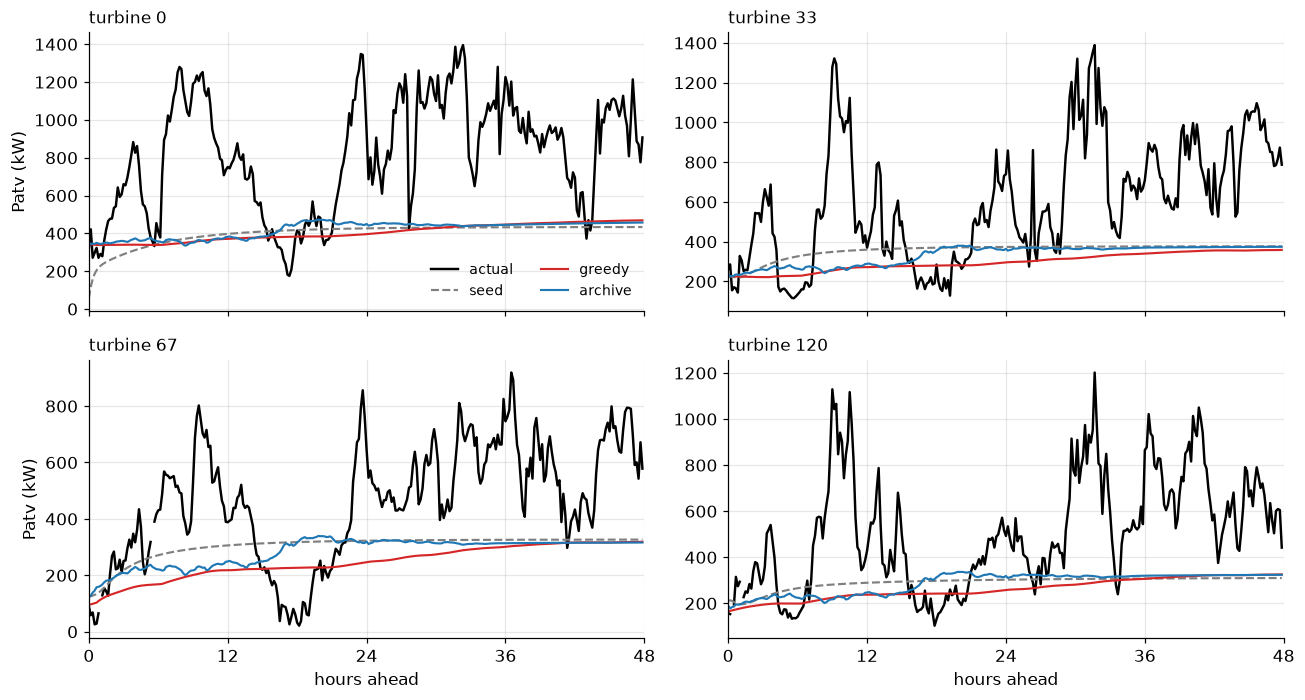

In [13]:
# Four individual turbines. This is where the seed's flatness shows.
sel = [0, 33, 67, 120]
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for ax, t in zip(axes.ravel(), sel):
    ax.plot(hours, y[t], color="black", lw=1.6, label="actual")
    ax.plot(hours, preds["seed"][t], color="tab:gray", lw=1.4, ls="--", label="seed")
    for k in ARMS:
        ax.plot(hours, preds[k][t], color=COL[k], lw=1.4, label=k)
    ax.set_title(f"turbine {t}", loc="left", fontsize=11)
    ax.set_xlim(0, 48); ax.set_xticks(range(0, 49, 12))
for ax in axes[1]: ax.set_xlabel("hours ahead")
for ax in axes[:, 0]: ax.set_ylabel("Patv (kW)")
axes[0, 0].legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout(); fig.savefig(FIGS / "forecast_turbines.png"); plt.show()

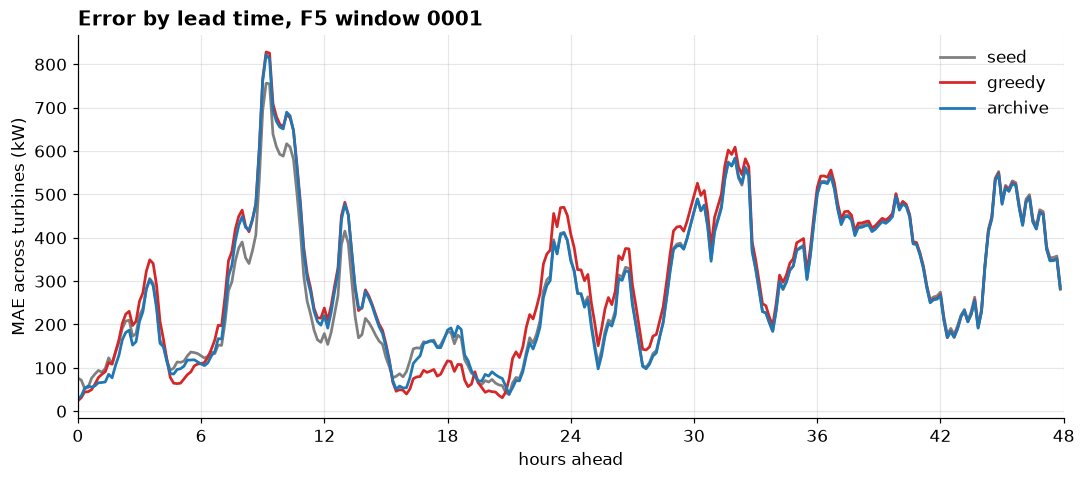

MAE (kW) on this window, first 6h vs last 6h
  seed     first  146.42   last  364.73
  greedy   first  143.06   last  359.60
  archive  first  128.80   last  358.29


In [14]:
# Error by lead time, averaged over turbines. Shows WHERE each program wins.
fig, ax = plt.subplots(figsize=(10, 4.5))
for lab, col in [("seed", "tab:gray")] + [(k, COL[k]) for k in ARMS]:
    mae_h = np.nanmean(np.abs(preds[lab] - y), axis=0)
    ax.plot(hours, mae_h, color=col, lw=1.8, label=lab)
ax.set_xlabel("hours ahead"); ax.set_ylabel("MAE across turbines (kW)")
ax.set_title(f"Error by lead time, {FOLD} window {WINDOW}",
             loc="left", fontsize=13, weight="bold")
ax.set_xlim(0, 48); ax.set_xticks(range(0, 49, 6)); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "error_by_lead_time.png"); plt.show()

print("MAE (kW) on this window, first 6h vs last 6h")
for lab in ["seed"] + list(ARMS):
    e = np.abs(preds[lab] - y)
    print(f"  {lab:8s} first {np.nanmean(e[:, :36]):7.2f}   last {np.nanmean(e[:, -36:]):7.2f}")

## 7. Competition test set

`evaluation/competition_score.py` over the locked `final_phase_test` (142 windows).
Run once per program, never as a search signal.

**Checkpoints must be trained on the full 245 days** for these numbers to sit in the
same table as the published baselines (climatology 50.487, ARMA 49.605, XGBoost
46.804, GRU 46.809) — that column was produced that way. The per-fold weights exist
for cross-validation only, where fold k must not see its own validation block; the
test set is days 246+, so training on 1–245 leaks nothing and is the protocol the
competition intended.

Both champions are ensembles with several hardcoded `{fold}` templates, so the
`SDWPF_GRU_CHECKPOINTS` override alone is not enough — every template is rewritten
in the copied file. Full-data weights live in directories named `FULL`, so the same
substitution machinery resolves them.

Run `retrain_full.sh` first (~4–5 h on an idle GPU).

In [15]:
import subprocess

TEST_DIR = os.environ.get(
    "SDWPF_TEST_DIR", str(Path.home() / "srip/wind_forecasting_data/sdwpf_kddcup/final_phase_test"))

def test_score(arm_dir, prog_id, pin="FULL", ckpt=None):
    """Score one program on the competition test set.

    pin  : string substituted for every "{fold}" template in the file. "FULL" is
           the full-245-day weights written by retrain_full.sh. None leaves the
           file alone (only valid when the program has no templates).
    ckpt : optional SDWPF_GRU_CHECKPOINTS override, for programs with a single
           CHECKPOINTS constant and no hardcoded member templates.
    """
    wd  = WS / arm_dir
    src = (wd / "archive" / f"{prog_id}.py").read_text()
    n   = src.count("{fold}")
    if pin is not None:
        src = src.replace("{fold}", pin)
    tmp = wd / f"_champion_{prog_id}.py"
    tmp.write_text(src)
    env = {**os.environ, "SDWPF_TEST_DIR": TEST_DIR}
    env.pop("SDWPF_GRU_CHECKPOINTS", None)
    if ckpt:
        env["SDWPF_GRU_CHECKPOINTS"] = ckpt
    try:
        out = subprocess.run(
            ["python", str(ROOT / "evaluation" / "competition_score.py"), str(tmp)],
            cwd=wd, env=env, capture_output=True, text=True, timeout=14400)
    finally:
        tmp.unlink(missing_ok=True)
    keys = ("competition_score", "total_mae", "total_rmse", "accuracy", "windows")
    tail = [l for l in out.stdout.splitlines() if any(x in l for x in keys)]
    print(f"=== {arm_dir} {prog_id}   ({n} templates" + (f" -> {pin})" if pin else ", left as-is)"))
    print("\n".join(tail) if tail else out.stdout[-1200:])
    if out.returncode: print("STDERR:", out.stderr[-900:])
    print()
    return out


In [16]:
# Anchor check: the seed program on the FULL-data checkpoints should reproduce the
# 46.809 already in the baseline table. If it does not, the champions' numbers will
# not be comparable to that table either, and the discrepancy has to be resolved
# before anything else is reported.
CKPT_FULL = ROOT / "baselines/gru/ckpt_full"
print("ckpt_full:", CKPT_FULL, "|", len(list(CKPT_FULL.glob("model_*.pt"))), "models")

_ = test_score(ARMS["greedy"], "001", pin=None, ckpt=str(CKPT_FULL))
print("expected 46.809 from the baseline table")


ckpt_full: /home/dorsa/srip/windevolve_sdwpf/baselines/gru/ckpt_full | 134 models
=== greedy-cv 001   (5 templates, left as-is)
  total_mae         : 41.993974
  total_rmse        : 51.623626
  competition_score : 46.808800   (0.5*(rmse+mae), lower is better)
  accuracy          : 60.6515%
  windows           : 142

expected 46.809 from the baseline table


In [ ]:
# Both champions on full-data weights. Run retrain_full.sh first.
for d in [WS / ARMS["greedy"] / ".cache" / "ckpt_005" / "FULL",
          WS / ARMS["greedy"] / ".cache" / "ckpt_085" / "FULL",
          WS / ARMS["archive"] / ".cache" / "ckpt_015" / "FULL",
          WS / ARMS["archive"] / ".cache" / "ckpt_009" / "FULL",
          WS / ARMS["archive"] / "checkpoints" / "FULL"]:
    print(f"{str(d):72s} {len(list(d.glob('model_*.pt'))) if d.is_dir() else 'MISSING':>8}")

_ = test_score(ARMS["greedy"],  CHAMP["greedy"].id,  pin="FULL")
_ = test_score(ARMS["archive"], CHAMP["archive"].id, pin="FULL")


In [ ]:
# Fill in the three test values from the cells above.
# Baseline table (all trained on the full 245 days):
#   climatology 50.487 | ARMA 49.605 | XGBoost 46.804 | GRU 46.809 | Baidu published 47.850
res = pd.DataFrame({
    "cv_5fold": [SEED, CHAMP["greedy"].score, CHAMP["archive"].score],
    "test":     [np.nan, np.nan, np.nan],
}, index=["GRU seed", f"greedy {CHAMP['greedy'].id}", f"archive {CHAMP['archive'].id}"])
res["cv_to_test_gap"]  = (res.test - res.cv_5fold).round(3)
res["vs_seed_on_test"] = (res.test - res.test.iloc[0]).round(3)
res["test_error_pct"]  = (res.test / CAPACITY * 100).round(2)
print(res.round(3).to_string())

print("""
The comparison this run exists to make — did 5-fold CV shrink the generalisation gap?

  aug10, single contiguous split (24 windows, days 198-245)
    seed     44.537 val -> 46.809 test   gap 2.272
    greedy   43.728     -> 47.738        gap 4.010
    archive  42.863     -> 48.209        gap 5.346
    both champions ended WORSE on test than the seed they started from.

  aug14, 5-fold rolling origin (75 windows)
    fill the gaps in above and compare. If the champion gaps land near the seed's
    rather than at 4-5 MW, the split change did its job.""")
